# 4. Bifurcation diagrams with AUTO

`m.auto.run` starts or continues a branch and returns the new points; `m.auto.diagram`
holds everything computed so far. AUTO's own table prints to `m.log`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyxpp
m = pyxpp.load("../lecar.ode")

## Start on a stable equilibrium

In [2]:
m.pars["iapp"] = 0.0
m.run(total=300)
m.run_last(total=10)
m.last_point()

{'V': -0.4956166446208954, 'W': 0.00027038261760026217}

## Equilibria as `iapp` varies

In [3]:
br = m.auto.run("iapp", start="steady",
                ds=0.01, dsmax=0.02, parmin=-0.2, parmax=0.5, nmax=2000)
br

<Diagram 67 points, labels 1:EP 2:LP 3:LP 4:HB 5:EP>

In [4]:
for p in br.labeled():
    print(f"{p.label:3d} {p.type:2s}  iapp={p.x:+.5f}  v={p.u0['v']:+.5f}  stable={p.stable}")

  1 EP  iapp=+0.00000  v=-0.49562  stable=True
  2 LP  iapp=+0.08326  v=-0.24491  stable=False
  3 LP  iapp=-0.02073  v=-0.03370  stable=False
  4 HB  iapp=+0.20384  v=+0.06953  stable=False
  5 EP  iapp=+0.51057  v=+0.12244  stable=True


## Periodic orbits from the Hopf point

In [5]:
hb = br.special("HB")[0]
po = m.auto.run(grab=hb.label, choice="periodic", dsmax=0.05, nmax=400)
print(m.transcript)
po

menu    Hopf Pt -> Periodic



<Diagram 103 points, labels 6:LP 7:BP 8:LP 9:LP 10:LP 11:BP 12:BP 13:MX>

Points of a periodic branch store the max, min and average of each variable over the cycle, and the period.

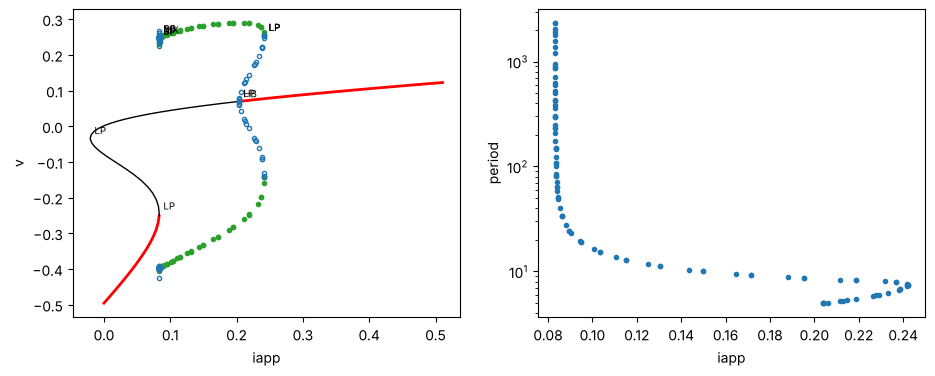

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
m.auto.diagram.plot(y="v", ax=ax[0])
ax[1].plot([p.x for p in po], [p.period for p in po], ".")
ax[1].set(xlabel="iapp", ylabel="period", yscale="log");

## The diagram as a table

In [7]:
df = m.auto.diagram.to_pandas(y="v")
df[df.label > 0]

,branch,pt,label,type,par,par2,ymax,ymin,norm,period,stable,periodic
0,1,1,1,EP,0.000000,0.333,-0.495617,-0.495617,0.495617,0.000000,True,False
14,1,15,2,LP,0.083257,0.333,-0.244914,-0.244914,0.245062,0.000000,False,False
29,1,30,3,LP,-0.020727,0.333,-0.033698,-0.033698,0.140663,0.000000,False,False
48,1,49,4,HB,0.203845,0.333,0.069535,0.069535,0.402518,4.985008,False,False
66,1,-67,5,EP,0.510574,0.333,0.122444,0.122444,0.589635,4.787754,True,False
76,-4,-10,6,LP,0.241962,NaN,0.255454,-0.143259,0.366231,7.436842,True,True
99,-4,-33,7,BP,0.083259,NaN,0.252312,-0.403444,0.246892,957.949137,True,True
131,-4,65,8,LP,0.241962,NaN,0.255411,-0.143011,0.366246,7.435887,False,True
136,-4,70,9,LP,0.203791,NaN,0.071000,0.068050,0.402486,4.985172,False,True
141,-4,-75,10,LP,0.241962,NaN,0.255385,-0.143213,0.366218,7.437691,True,True


## Two-parameter continuation of the fold

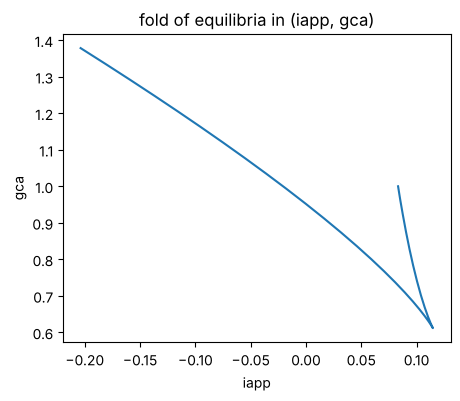

In [8]:
lp = br.special("LP")[0]
two = m.auto.run(grab=lp.label, param2="gca", nmax=400, parmin=-0.2, parmax=0.6)
fig, ax = plt.subplots(figsize=(5, 4))
m.auto.diagram.plot(two_par=True, ax=ax)
ax.set_title("fold of equilibria in (iapp, gca)");

## Settings, buttons and files

In [9]:
s = m.auto.settings
{k: s[k] for k in ("param", "param2", "ntst", "nmax", "ds", "dsmax", "parmin", "parmax")}

{'param': 'iapp',
 'param2': 'gca',
 'ntst': 15,
 'nmax': 400,
 'ds': 0.01,
 'dsmax': 0.05,
 'parmin': -0.2,
 'parmax': 0.6}

In [10]:
pyxpp.show(m.auto.buttons)

parameter              [P]  Choose up to 8 AUTO parameters (dialog Par1..Par8)
axes                   [A]  Plot type and axes
  hi                     [H]  Hi
  norm                   [N]  Norm
  hi_lo                  [I]  hI-lo
  period                 [P]  Period
  two_par                [T]  Two par
  zoom_in                [Z]  (Z)oom in
  zoom_out               [O]  Zoom (O)ut
  last_1_par             [1]  last 1 par
  last_2_par             [2]  last 2 par
  fit                    [F]  Fit
  frequency              [R]  fRequency
  average                [A]  Average
  default                [D]  Default
  scroll                 [S]  Scroll
numerics               [N]  Continuation numerics (dialog AutoNum)
run                    [R]  Run AUTO; asks what to do at the grabbed point
grab                   [G]  Pick a point: label n, or '#k' for the k-th point
usr_period             [U]  User-defined output values
clear                  [C]  Clear the plot
redraw                 [D] 

In [11]:
m.auto.write_pts("lecar_bif.dat")      # File > Write pts
print(open(m.workdir / "lecar_bif.dat").read()[:300])

0 -0.495617 -0.495617 2 1 0
0.00850324 -0.477514 -0.477514 1 1 0
0.0168951 -0.45936 -0.45936 1 1 0
0.0251467 -0.441142 -0.441142 1 1 0
0.0332214 -0.422845 -0.422845 1 1 0
0.0410722 -0.404452 -0.404452 1 1 0
0.0486388 -0.385941 -0.385941 1 1 0
0.0558433 -0.367287 -0.367287 1 1 0
0.0625844 -0.348463 -


AUTO's own output:

In [12]:
types = {"EP", "LP", "HB", "BP", "PD", "TR", "MX", "UZ"}
rows = [l for l in m.log.splitlines()
        if "BR    PT" in l or (len(l.split()) > 3 and l.split()[2] in types)]
print("\n".join(rows[:25]))

  BR    PT  TY LAB    PAR(0)        L2-NORM         U(1)          U(2)     
   1     1  EP   1  0.000000E+00  4.956167E-01 -4.956166E-01  2.703826E-04
   1    15  LP   2  8.325657E-02  2.450622E-01 -2.449143E-01  8.514462E-03
   1    30  LP   3 -2.072714E-02  1.406626E-01 -3.369752E-02  1.365667E-01
   1    49  HB   4  2.038448E-01  4.025181E-01  6.953479E-02  3.964666E-01
   1    67  EP   5  5.105744E-01  5.896349E-01  1.224442E-01  5.767814E-01
  BR    PT  TY LAB    PAR(0)        L2-NORM       MAX(1)        MAX(2)     
   4    10  LP   6  2.419618E-01  3.662311E-01  2.554537E-01  4.837387E-01
   4    33  BP   7  8.325942E-02  2.468922E-01  2.523122E-01  4.207457E-01
   4    65  LP   8  2.419620E-01  3.662463E-01  2.554113E-01  4.837907E-01
   4    70  LP   9  2.037912E-01  4.024858E-01  7.099997E-02  3.976818E-01
   4    75  LP  10  2.419618E-01  3.662176E-01  2.553848E-01  4.836393E-01
   4    98  BP  11  8.325760E-02  2.461520E-01  2.479350E-01  3.968808E-01
   4   100  BP  12  8.3